# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170361          # <-- your full roll number
NAME = "Aditya Mehta"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170361   Name: Aditya Mehta   Fingerprint: B38B9E25   Tickets: 13

Ticket_ID                                                                                     Ticket_Text
      T01                                      The projector keeps asking for login. It worked yesterday.
      T02                                                 The VPN keeps asking for login. This is urgent.
      T03                               Lms is running slowly during the lab. I have tried several times!
      T04                                           The printer has stopped syncing. It worked yesterday.
      T05 I was locked out of the student portal after restarting the system. I have tried several times!
      T06                                  I was locked out of the email since yesterday. This is urgent.
      T07                                                                     My roll no. is 1023-03-021.
      T08                 I can't open the VPN when connected to cam

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Q1: Preprocessing pipeline
processed = [process_ticket(text) for text in df["Ticket_Text"]]

rows = []
for ticket_id, result in zip(df["Ticket_ID"], processed):
    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

preprocessing_table = pd.DataFrame(rows)

# Unique tokens in the total row means unique token types across the whole dataset,
# rather than adding each ticket's unique-token count.
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(x["sentences"]) for x in processed),
    "Tokens": sum(len(x["tokens"]) for x in processed),
    "Punctuation Tokens": sum(len(x["punct"]) for x in processed),
    "Stopwords": sum(len(x["stops"]) for x in processed),
    "Unique Tokens": len(set(t for x in processed for t in x["tokens"])),
    "Final Tokens": sum(len(x["final"]) for x in processed)
}
preprocessing_table = pd.concat(
    [preprocessing_table, pd.DataFrame([total_row])], ignore_index=True
)
display(preprocessing_table)

# Show the actual components for one focus ticket, or T01 if FOCUS is unavailable.
focus_id = FOCUS[0] if FOCUS else df.loc[0, "Ticket_ID"]
focus_idx = df.index[df["Ticket_ID"] == focus_id][0]
focus_result = processed[focus_idx]
print("Selected ticket:", focus_id)
print("Raw text:", df.loc[focus_idx, "Ticket_Text"])
print("Sentences:", focus_result["sentences"])
print("Tokens:", focus_result["tokens"])
print("Punctuation tokens:", focus_result["punct"])
print("Stopwords:", focus_result["stops"])
print("Final tokens:", focus_result["final"])

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,11,2,3,10,6
1,T02,2,11,2,4,10,5
2,T03,2,14,2,5,14,7
3,T04,2,10,2,3,9,5
4,T05,2,19,2,9,17,8
5,T06,2,14,2,7,13,5
6,T07,2,7,2,3,6,2
7,T08,2,19,2,7,16,10
8,T09,2,17,2,6,15,9
9,T10,2,10,2,2,9,6


Selected ticket: T09
Raw text: I keep getting logged out of the student portal before the assignment deadline. Please help.
Sentences: ['I keep getting logged out of the student portal before the assignment deadline.', 'Please help.']
Tokens: ['i', 'keep', 'getting', 'logged', 'out', 'of', 'the', 'student', 'portal', 'before', 'the', 'assignment', 'deadline', '.', 'please', 'help', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['i', 'out', 'of', 'the', 'before', 'the']
Final tokens: ['keep', 'getting', 'logged', 'student', 'portal', 'assignment', 'deadline', 'please', 'help']


**Observation:** The official pipeline lowercases tokens and removes punctuation and English stopwords. Final tokens such as `n't`, `'s`, or `ca` can remain because `word_tokenize()` splits contractions into multiple pieces; those pieces are not always present in NLTK's stopword list in the same form. The exact examples are printed by the preprocessing cell for the selected ticket.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

In [8]:
# Q2: Regular expressions on raw tickets and TEST_LINES
import re

raw_tickets = df["Ticket_Text"].tolist()

# Long words: more than five alphabetic letters.
long_word_pattern = r"\b[A-Za-z]{6,}\b"
# Integers, decimals and dotted version numbers as one match.
number_pattern = r"(?<![\w.])\d+(?:\.\d+)*(?![\w.])"
capitalized_pattern = r"\b[A-Z][A-Za-z]*\b"
vowel_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"

for label, pattern in [
    ("Words longer than 5 letters", long_word_pattern),
    ("Numbers / decimals / versions", number_pattern),
    ("Capitalized words", capitalized_pattern),
    ("Words starting with a vowel", vowel_pattern)
]:
    print("\\n" + label)
    for ticket_id, text in zip(df["Ticket_ID"], raw_tickets):
        print(ticket_id, re.findall(pattern, text))

# The same patterns are checked against the required TEST_LINES.
print("\\nREGEX EXTRACTION ON TEST_LINES")
for i, line in enumerate(TEST_LINES, 1):
    print(f"Line {i}:")
    print(" long words:", re.findall(long_word_pattern, line))
    print(" numbers:", re.findall(number_pattern, line))
    print(" capitalized:", re.findall(capitalized_pattern, line))
    print(" vowel-starting:", re.findall(vowel_pattern, line))

# Replacement: URLs are matched before phone numbers to avoid overlap.
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"\b(?:https?://|www\.)[^\s<>]+"
phone_pattern = r"(?<!\w)(?:\+?91[-.\s]?)?(?:\d{5}[-.\s]?\d{5}|\d{3,4}[-.\s]?\d{3}[-.\s]?\d{4})(?!\w)"

def redact_contact_details(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, lambda m: m.group(0).rstrip(".,!?;:"), text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\\nREPLACEMENT ON RAW TICKETS")
for ticket_id, text in zip(df["Ticket_ID"], raw_tickets):
    print(ticket_id, redact_contact_details(text))

print("\\nREPLACEMENT ON TEST_LINES")
for i, line in enumerate(TEST_LINES, 1):
    print(i, redact_contact_details(line))

# Count capitalized words that are capitalized only because they start a sentence.
sentence_initial_capitalized = []
for text in raw_tickets:
    for sentence in sent_tokenize(text):
        first = re.match(r"\s*([A-Z][A-Za-z]*)\b", sentence)
        if first:
            sentence_initial_capitalized.append(first.group(1))
print("\\nSentence-initial capitalized words (occurrences):",
      sentence_initial_capitalized)
print("Count of sentence-initial occurrences:", len(sentence_initial_capitalized))

\nWords longer than 5 letters
T01 ['projector', 'asking', 'worked', 'yesterday']
T02 ['asking', 'urgent']
T03 ['running', 'slowly', 'during', 'several']
T04 ['printer', 'stopped', 'syncing', 'worked', 'yesterday']
T05 ['locked', 'student', 'portal', 'restarting', 'system', 'several']
T06 ['locked', 'yesterday', 'urgent']
T07 []
T08 ['connected', 'campus', 'changed']
T09 ['getting', 'logged', 'student', 'portal', 'before', 'assignment', 'deadline', 'Please']
T10 ['Projector', 'working', 'yesterday', 'Please']
T11 ['printer', 'jammed']
T12 ['Version', 'crashes']
T13 ['closed']
\nNumbers / decimals / versions
T01 []
T02 []
T03 []
T04 []
T05 []
T06 []
T07 ['1023', '03']
T08 []
T09 []
T10 []
T11 []
T12 ['2.0.1', '99']
T13 ['3']
\nCapitalized words
T01 ['The', 'It']
T02 ['The', 'VPN', 'This']
T03 ['Lms', 'I']
T04 ['The', 'It']
T05 ['I', 'I']
T06 ['I', 'This']
T07 ['My']
T08 ['I', 'VPN', 'Wi', 'Fi', 'I']
T09 ['I', 'Please']
T10 ['Projector', 'Please']
T11 ['The']
T12 ['Version']
T13 ['The', '

**Observation:** Capitalized-word extraction also captures words that are capitalized only because they begin a sentence, such as `The`, `I`, and `My`. The code below counts sentence-initial capitalized matches in this dataset; names/acronyms such as `VPN` and `Lms` can also be capitalized for other reasons.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [12]:
# Q3: One RegexpTokenizer pattern preserving requested token types
# Alternatives are ordered from more specific to more general.
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

custom_pattern = r"""
    (?:https?://|www\.)[^\s<>]+
    |
    [A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}
    |
    (?:\+?91[-.\s]?)?\d{5}[-.\s]?\d{5}
    |
    (?:\+?\d{1,3}[-.\s]?)?(?:\d{3,4}[-.\s]?)\d{3}[-.\s]?\d{4}
    |
    \d+(?:\.\d+)+
    |
    [A-Za-z]+(?:[-'][A-Za-z]+)*
    |
    \d+
    |
    [^\w\s]
"""
custom_tokenizer = RegexpTokenizer(custom_pattern, flags=re.VERBOSE)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("CUSTOM TOKENIZER VS word_tokenize() ON TEST_LINES")
for line in TEST_LINES:
    print("\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

print("\nCUSTOM TOKENIZER VS word_tokenize() ON TICKETS")
different_ticket_ids = []
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    mine = my_tokenize(text)
    nltk_tokens = word_tokenize(text)
    if mine != nltk_tokens:
        different_ticket_ids.append(ticket_id)
    print(ticket_id, "\n custom:", mine, "\n NLTK:  ", nltk_tokens)

print("\nNumber of tickets with different tokenization:",
      len(different_ticket_ids))
print("Ticket IDs:", different_ticket_ids)

CUSTOM TOKENIZER VS word_tokenize() ON TEST_LINES

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab i

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

There are **4** tickets tokenized differently by `my_tokenize` and `word_tokenize`. These are ticket IDs: **T07, T08, T11, and T13**.

* **T07**: `my_tokenize` splits the hyphenated roll number `'1023-03-021'` into individual numeric components (`['1023', '-', '03', '-', '021']`), whereas NLTK's `word_tokenize` keeps it as a single token (`'1023-03-021'`).
* **T08** & **T11**: `my_tokenize` preserves contractions as single units (e.g., `"can't"`, `"don't"`, `"won't"`, `"isn't"`), whereas `word_tokenize` splits them (e.g., `['ca', "n't"]`, `['wo', "n't"]`).
* **T13**: `my_tokenize` separates `'Lab-3'` into `['Lab', '-', '3']`, while `word_tokenize` treats `'Lab-3'` as a single token.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [13]:
# Q4: Compare stemming and POS-aware lemmatization on unique final tokens
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

porter = PorterStemmer()
lancaster = LancasterStemmer()
# Looking at the ticket text, several words end in -ing (e.g. running, syncing,
# restarting, working). The -ing rule is therefore a dataset-grounded suffix choice.
regexp_stemmer = RegexpStemmer(r"ing$")
lemmatizer = WordNetLemmatizer()

def wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("R"):
        return "r"
    return "n"

S3 = [token for result in processed for token in result["final"]]
unique_final_tokens = sorted(set(S3))
tagged_words = nltk.pos_tag(unique_final_tokens)

stem_rows = []
for word, tag in tagged_words:
    pos = wordnet_pos(tag)
    stem_rows.append({
        "Word": word,
        "POS": tag,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "WordNet Lemma": lemmatizer.lemmatize(word, pos=pos)
    })

stem_table = pd.DataFrame(stem_rows)
method_cols = ["Porter", "Lancaster", "Regexp", "WordNet Lemma"]
different_stems = stem_table[stem_table[method_cols].nunique(axis=1) > 1]
display(different_stems)

suffix_examples = [w for w in unique_final_tokens if w.endswith("ing")]
print("Dataset words ending in -ing:", suffix_examples)
print("Regexp stemmer removes only the final 'ing' from these words.")

# Print candidate examples for discussing over-/under-stemming.
print("\\nPotential over-stemming examples (inspect outputs):")
display(different_stems.head(10))

,Word,POS,Porter,Lancaster,Regexp,WordNet Lemma
4,assignment,NN,assign,assign,assignment,assignment
6,campus,VB,campu,camp,campus,campus
7,changed,VBD,chang,chang,changed,change
8,closed,JJ,close,clos,closed,closed
9,connected,VBN,connect,connect,connected,connect
10,crashes,NNS,crash,crash,crashes,crash
11,deadline,VBP,deadlin,deadlin,deadline,deadline
13,getting,VBG,get,get,gett,get
15,jammed,VBD,jam,jam,jammed,jam
17,keeps,NNS,keep,keep,keeps,keep


Dataset words ending in -ing: ['asking', 'getting', 'restarting', 'running', 'syncing', 'working']
Regexp stemmer removes only the final 'ing' from these words.
\nPotential over-stemming examples (inspect outputs):


,Word,POS,Porter,Lancaster,Regexp,WordNet Lemma
4,assignment,NN,assign,assign,assignment,assignment
6,campus,VB,campu,camp,campus,campus
7,changed,VBD,chang,chang,changed,change
8,closed,JJ,close,clos,closed,closed
9,connected,VBN,connect,connect,connected,connect
10,crashes,NNS,crash,crash,crashes,crash
11,deadline,VBP,deadlin,deadlin,deadline,deadline
13,getting,VBG,get,get,gett,get
15,jammed,VBD,jam,jam,jammed,jam
17,keeps,NNS,keep,keep,keeps,keep


**Observation:** Over-stemming happens when a stemmer removes too much and merges words that should remain distinct; under-stemming happens when related word forms are not reduced to a shared stem. Use the displayed comparison table to select one actual over-stemming and one under-stemming example from this dataset. Porter and Lancaster can differ because they use different suffix rules, while the RegexpStemmer only removes the chosen `-ing` suffix and does not understand word meaning.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Total tokens,Unique tokens,TTR
S1,159.0,81.0,0.5094
S2,132.0,75.0,0.5682
S3,77.0,53.0,0.6883
S4,77.0,51.0,0.6623


Top 10 words of S1:
[('.', 21), ('the', 12), ('is', 7), ('i', 7), ('yesterday', 4), ("n't", 4), ('it', 3), ('out', 3), ('of', 3), ('projector', 2)]
\nTop 10 words of S3:
[('yesterday', 4), ("n't", 4), ('projector', 2), ('keeps', 2), ('asking', 2), ('login', 2), ('worked', 2), ('vpn', 2), ('urgent', 2), ('lab', 2)]


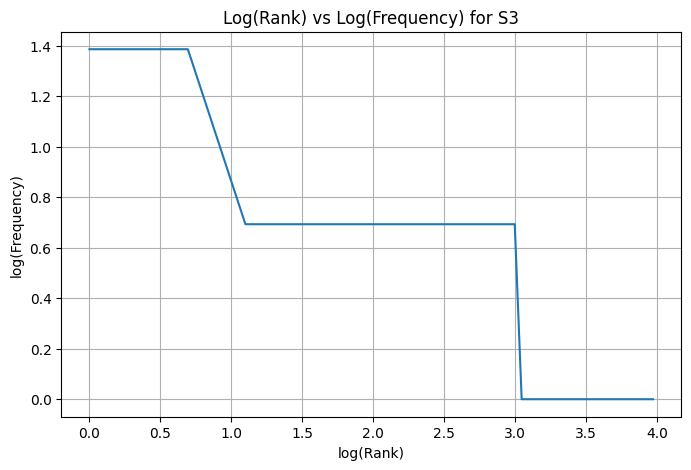

Top 5 bigrams of S1:
[(('.', 'i'), 6), (('yesterday', '.'), 4), (('.', 'the'), 3), (('out', 'of'), 3), (('of', 'the'), 3)]
\nTop 5 bigrams of S3:
[(('keeps', 'asking'), 2), (('asking', 'login'), 2), (('worked', 'yesterday'), 2), (('tried', 'several'), 2), (('several', 'times'), 2)]


In [14]:
# Q5: Corpus statistics, frequency lists, log-rank plot and bigrams
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import ngrams

# S1: all tokens, including punctuation
S1 = [token for result in processed for token in result["tokens"]]
# S2: tokens without punctuation
S2 = [token for token in S1 if not is_punct(token)]
# S3: official final tokens
S3 = [token for result in processed for token in result["final"]]
# S4: S3 after Porter stemming
S4 = [porter.stem(token) for token in S3]

def corpus_stats(corpus):
    total = len(corpus)
    unique = len(set(corpus))
    return {
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": round(unique / total, 4) if total else 0.0
    }

statistics_table = pd.DataFrame({
    "S1": corpus_stats(S1),
    "S2": corpus_stats(S2),
    "S3": corpus_stats(S3),
    "S4": corpus_stats(S4)
}).T
display(statistics_table)

print("Top 10 words of S1:")
print(Counter(S1).most_common(10))
print("\\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

ranked = Counter(S3).most_common()
ranks = list(range(1, len(ranked) + 1))
frequencies = [frequency for _, frequency in ranked]

plt.figure(figsize=(8, 5))
plt.plot([math.log(rank) for rank in ranks],
         [math.log(freq) for freq in frequencies])
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

print("Top 5 bigrams of S1:")
print(Counter(ngrams(S1, 2)).most_common(5))
print("\\nTop 5 bigrams of S3:")
print(Counter(ngrams(S3, 2)).most_common(5))

**Observation:** TTR changes from S1 to S4 because S1 includes punctuation and all token forms, while S4 contains only final tokens after Porter stemming. Removing punctuation and stopwords changes both the total and unique-token counts. Stemming can merge related forms into one stem, reducing the number of unique types. Use the printed statistics table to state the actual TTR values and whether TTR increased or decreased for this dataset.

Q6


(a) Why does TTR change from S1 to S4 in your dataset?

TTR changes because S1 contains all tokens, including punctuation, whereas S4 contains final tokens after Porter stemming. Stemming combines related word forms into common stems, reducing the number of unique tokens and generally lowering TTR.

(b) Give one example where `word_tokenize()` and your tokenizer differ. Explain the difference.

For the ticket “I can't open the VPN…”, my custom tokenizer preserves `can't` as a single token, whereas `word_tokenize()` splits it into `ca` and `n't`. This happens because the custom tokenizer treats contractions as single units.

(c) Give one example where stemming produces an undesirable result.

The word `state-of-the-art` may be handled poorly by a suffix-based stemmer if it removes a suffix without considering the word's meaning. Stemming can produce incorrect or meaningless forms because it relies on rules rather than understanding context.

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

For the word `running` used as a verb, POS-aware lemmatization produces `run`, its dictionary form. Unlike stemming, lemmatization uses grammatical information to identify the correct base form while preserving meaning.